# 03 · Evaluate on the test split

Works for YOLO (`.pt`), RF-DETR (`.pth`) and the per-pixel BioTrove model from `05_biotrove_semseg.ipynb` (`checkpoint_best.pth`), all scored the same way on the COCO test split so results are comparable.

Reports mask mAP per class (instance models only) and coverage-% MAE: predicted % vs % computed from ground-truth masks
(disease pixels inside the largest leaf / leaf pixels). Target MAE < 5 percentage points per disease.
Per-pixel metrics for every model: IoU per class and image-level coverage (disease % of all leaf pixels in the image).

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from dotenv import load_dotenv
from PIL import Image
from pycocotools import mask as mask_utils
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

ROOT = Path.cwd()
load_dotenv(ROOT / ".env")

DATA_VERSION = f"v{os.environ['ROBOFLOW_VERSION']}"
DATA_NAME = f"{os.environ['ROBOFLOW_PROJECT']}-{DATA_VERSION}"  # e.g. leaf-dis-seg-v1
DATASET_DIR = ROOT / "datasets" / f"{DATA_NAME}-coco"
TEST_DIR = DATASET_DIR / "test"
YOLO_DATA = ROOT / "datasets" / f"{DATA_NAME}-yolo" / "data.yaml"

RUN_TAG = ""  # "" = runs/yolo26x-seg_data-v2 (trained Nov 4); "_lds" = a retrain with the 02 settings
CHECKPOINT = ROOT / "runs" / f"yolo26x-seg_data-{DATA_VERSION}{RUN_TAG}" / "weights" / "best.pt"
# CHECKPOINT = ROOT / "runs" / "yolo26x-seg_data-v1" / "weights" / "best.pt"  # the v1 model on this test set
# CHECKPOINT = ROOT / "runs" / f"rfdetr-seg-medium-default_data-{DATA_VERSION}" / "checkpoint_best_total.pth"
# CHECKPOINT = ROOT / "runs" / f"semseg-biotrove-b16_data-{DATA_VERSION}" / "checkpoint_best.pth"
THRESHOLD = 0.5  # confidence used for coverage and the pictures; mAP uses every prediction

DISEASES = ("leaf_spot", "powdery_mildew")
COLORS = {"leaf": (0, 200, 0), "leaf_spot": (230, 120, 0), "powdery_mildew": (180, 0, 220)}
print("data:", DATA_NAME, "| checkpoint:", CHECKPOINT.relative_to(ROOT))

data: lds_v1-v2 | checkpoint: runs\yolo26x-seg_data-v2\weights\best.pt


## Load the model

`predict(image)` returns `(masks [N, H, W] bool at full image size, class names [N], confidences [N])` for every model type (see `eval_utils.py`).
For the per-pixel model, each connected leaf region is one "leaf" and each disease is one mask covering all its pixels.

In [2]:
from eval_utils import load_predictor

coco_gt = COCO(str(TEST_DIR / "_annotations.coco.json"))
cat_names = {c["id"]: c["name"] for c in coco_gt.loadCats(coco_gt.getCatIds())}
cat_ids = {name: cid for cid, name in cat_names.items()}

KIND, predict, model = load_predictor(CHECKPOINT, cat_names)  # KIND: "yolo", "rfdetr" or "semseg"
IS_YOLO = KIND == "yolo"
print(KIND, CHECKPOINT.name, "| dataset classes:", cat_names)

C:\Users\bp67339\PCPL\plant disease detection\training\training_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


loading annotations into memory...
Done (t=0.03s)
creating index...
index created!


yolo best.pt | dataset classes: {0: 'LDS-V1', 1: 'leaf', 2: 'leaf_spot', 3: 'powdery_mildew'}


## Run predictions on every test image

In [3]:
predictions = {}  # image_id -> (masks, class names, confidences)
for img in coco_gt.loadImgs(coco_gt.getImgIds()):
    image = Image.open(TEST_DIR / img["file_name"]).convert("RGB")
    predictions[img["id"]] = predict(image)

predicted_names = {n for _, names, _ in predictions.values() for n in names}
print("predicted classes:", sorted(predicted_names))
assert predicted_names <= set(cat_ids), "model class names don't match the dataset categories"

predicted classes: [np.str_('leaf'), np.str_('leaf_spot'), np.str_('powdery_mildew')]


## Mask mAP

Instance models only. mAP scores separate objects, which a per-pixel model doesn't produce; for it, use the per-pixel IoU section below.

In [4]:
def mask_map(cat_ids=None):
    ev = COCOeval(coco_gt, coco_dt, iouType="segm")
    if cat_ids:
        ev.params.catIds = cat_ids
    ev.evaluate(); ev.accumulate(); ev.summarize()
    return ev.stats[0], ev.stats[1]  # mAP@[.5:.95], mAP@.5


if KIND == "semseg":
    print("per-pixel model: mask mAP skipped (see per-pixel IoU below)")
else:
    results = []
    for image_id, (masks, names, confidences) in predictions.items():
        for m, n, s in zip(masks, names, confidences):
            rle = mask_utils.encode(np.asfortranarray(m.astype(np.uint8)))
            results.append({"image_id": image_id, "category_id": cat_ids[n], "segmentation": rle, "score": float(s)})

    coco_dt = coco_gt.loadRes(results)
    overall = mask_map()
    per_class = {
        name: mask_map([cid])
        for cid, name in cat_names.items()
        if coco_gt.getAnnIds(catIds=[cid])
    }

Loading and preparing results...
DONE (t=0.07s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*


DONE (t=1.93s).
Accumulating evaluation results...
DONE (t=0.03s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.367
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.621
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.367
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.155
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.490
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.489
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.027
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.202
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.451
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.223
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.618
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= lar

DONE (t=0.37s).
Accumulating evaluation results...
DONE (t=0.01s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.507
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.655
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.567
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.011
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.413
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.700
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.046
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.348
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.597
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.020
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.682
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= lar

DONE (t=1.18s).
Accumulating evaluation results...
DONE (t=0.02s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.322
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.669
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.271
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.258
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.630
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.584
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.016
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.119
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.381
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.326
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.670
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= lar

DONE (t=0.30s).
Accumulating evaluation results...
DONE (t=0.01s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.274
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.538
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.262
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.195
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.426
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.182
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.018
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.139
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.377
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.323
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.502
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= lar

In [5]:
if KIND != "semseg":
    print(f"{'class':<16}{'mAP50-95':>10}{'mAP50':>10}")
    for name, (m, m50) in {**per_class, "ALL": overall}.items():
        print(f"{name:<16}{m:>10.3f}{m50:>10.3f}")

class             mAP50-95     mAP50
leaf                 0.507     0.655
leaf_spot            0.322     0.669
powdery_mildew       0.274     0.538
ALL                  0.367     0.621


### YOLO only: Ultralytics metrics per class, validation and test splits

Ultralytics' own `val()` on both splits at the training image size, with box and mask precision, recall, F1, mAP50 and mAP50-95 for each class. P, R and F1 are at the confidence that maximises mean F1. The table is also saved as `results/ultralytics_metrics_<run>.csv`.
Expect small differences from the pycocotools numbers above, which use a different mask resolution and AP interpolation.

In [6]:
import csv


def f1(p, r):
    return 2 * p * r / (p + r) if p + r else 0.0


if IS_YOLO:
    imgsz = model.ckpt["train_args"]["imgsz"] if getattr(model, "ckpt", None) else 1024
    rows = []
    for split in ("val", "test"):
        m = model.val(data=str(YOLO_DATA), split=split, imgsz=imgsz, batch=8, workers=0, plots=False, verbose=False)
        counts = getattr(m, "nt_per_class", None)  # labelled instances per class id (if this Ultralytics version has it)
        per_class = [(model.names[int(c)], j) for j, c in enumerate(m.ap_class_index)]
        for name, j in per_class:
            bp, br, b50, b = m.box.class_result(j)
            sp, sr, s50, s = m.seg.class_result(j)
            rows.append({"split": split, "class": name,
                         "instances": int(counts[int(m.ap_class_index[j])]) if counts is not None else "",
                         "box_P": bp, "box_R": br, "box_F1": f1(bp, br), "box_mAP50": b50, "box_mAP50-95": b,
                         "mask_P": sp, "mask_R": sr, "mask_F1": f1(sp, sr), "mask_mAP50": s50, "mask_mAP50-95": s})
        rows.append({"split": split, "class": "all", "instances": int(sum(counts)) if counts is not None else "",
                     "box_P": m.box.mp, "box_R": m.box.mr, "box_F1": f1(m.box.mp, m.box.mr), "box_mAP50": m.box.map50,
                     "box_mAP50-95": m.box.map, "mask_P": m.seg.mp, "mask_R": m.seg.mr, "mask_F1": f1(m.seg.mp, m.seg.mr),
                     "mask_mAP50": m.seg.map50, "mask_mAP50-95": m.seg.map})

    cols = ["box_P", "box_R", "box_F1", "box_mAP50", "box_mAP50-95", "mask_P", "mask_R", "mask_F1", "mask_mAP50", "mask_mAP50-95"]
    for split in ("val", "test"):
        print(f"\n{split} split ({CHECKPOINT.relative_to(ROOT)}, imgsz {imgsz})")
        print(f"{'class':<16}{'inst':>6}" + "".join(f"{c:>14}" for c in cols))
        for r in rows:
            if r["split"] == split:
                print(f"{r['class']:<16}{r['instances']!s:>6}" + "".join(f"{float(r[c]):>14.3f}" for c in cols))

    RESULTS = ROOT / "results"
    RESULTS.mkdir(exist_ok=True)
    out_csv = RESULTS / f"ultralytics_metrics_{CHECKPOINT.parent.parent.name}.csv"
    with open(out_csv, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0]))
        w.writeheader(); w.writerows(rows)
    print("\nsaved", out_csv.relative_to(ROOT))

Ultralytics 8.4.184  Python-3.13.14 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX PRO 5000 Blackwell, 48935MiB)


YOLO26x-seg summary (fused): 204 layers, 62,730,197 parameters, 0 gradients, 313.5 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 244.7±95.7 MB/s, size: 144.5 KB)


val: Scanning C:\Users\bp67339\PCPL\plant disease detection\training\datasets\lds_v1-v2-yolo\valid\labels.cache... 146 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 146/146 19.8Mit/s 0.0s

val: C:\Users\bp67339\PCPL\plant disease detection\training\datasets\lds_v1-v2-yolo\valid\images\IMG_1846_JPG_jpg.rf.fe64a5a31a2e9b6ff40dbe68bbccb499.jpg: 1 duplicate labels removed
val: C:\Users\bp67339\PCPL\plant disease detection\training\datasets\lds_v1-v2-yolo\valid\images\IMG_1872_JPG_jpg.rf.9674923cf927d2a896558fda5853b2d8.jpg: 1 duplicate labels removed
val: C:\Users\bp67339\PCPL\plant disease detection\training\datasets\lds_v1-v2-yolo\valid\images\IMG_1939_JPG_jpg.rf.f00535048e7209ed3fddb9d9636084bd.jpg: 3 duplicate labels removed


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 5% ╸─────────── 1/19 1.5s/it 0.4s<26.7s

... (34 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.1it/s 3.2s

                   all         76       5330      0.756      0.627      0.679      0.441      0.715      0.562      0.594      0.343


Speed: 0.3ms preprocess, 19.2ms inference, 0.0ms loss, 1.5ms postprocess per image



val split (runs\yolo26x-seg_data-v2\weights\best.pt, imgsz 1024)
class             inst         box_P         box_R        box_F1     box_mAP50  box_mAP50-95        mask_P        mask_R       mask_F1    mask_mAP50 mask_mAP50-95
leaf              2478         0.754         0.670         0.710         0.694         0.583         0.772         0.657         0.710         0.690         0.564
leaf_spot         5789         0.802         0.658         0.723         0.733         0.410         0.727         0.564         0.635         0.638         0.289
powdery_mildew    1232         0.664         0.582         0.620         0.620         0.368         0.637         0.526         0.576         0.544         0.271
all               9499         0.740         0.637         0.685         0.683         0.454         0.712         0.583         0.641         0.624         0.374

test split (runs\yolo26x-seg_data-v2\weights\best.pt, imgsz 1024)
class             inst         box_P         box_R  

## Coverage-% MAE

Same rule as the backend: primary leaf = largest leaf mask; disease % = disease pixels inside that leaf / leaf pixels × 100.

In [7]:
from eval_utils import coverage_primary_leaf as coverage

errors = {d: [] for d in DISEASES}
no_gt_leaf, missed_leaf = 0, 0
for image_id, (masks, names, confidences) in predictions.items():
    anns = coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=image_id))
    gt = coverage([coco_gt.annToMask(a).astype(bool) for a in anns], [cat_names[a["category_id"]] for a in anns])
    keep = confidences >= THRESHOLD
    pred = coverage(masks[keep], names[keep])
    if gt is None:
        no_gt_leaf += 1
    elif pred is None:
        missed_leaf += 1
    else:
        for d in DISEASES:
            errors[d].append(abs(pred[d] - gt[d]))

print(f"images without a GT leaf: {no_gt_leaf} | GT leaf but none predicted: {missed_leaf}")
for d, e in errors.items():
    mae = np.mean(e)
    print(f"{d:<16} MAE {mae:5.2f} pp  (n={len(e)})  {'OK' if mae < 5 else 'above 5 pp target'}")

images without a GT leaf: 0 | GT leaf but none predicted: 0
leaf_spot        MAE  0.37 pp  (n=76)  OK
powdery_mildew   MAE  0.49 pp  (n=76)  OK


## Per-pixel IoU and image-level coverage (all models)

Ground truth and predictions are both turned into one class map per image (leaves first, diseases painted on top; predictions above `THRESHOLD`).
- **IoU per class** over all test pixels; mIoU over leaf + diseases.
- **Image-level coverage**: disease pixels ÷ all leaf pixels in the image. It doesn't need separate leaves, so it is the fair coverage comparison between instance models (YOLO, RF-DETR) and the per-pixel model. (The primary-leaf coverage above favors instance models: the per-pixel model merges touching leaves.)

In [8]:
from eval_utils import CLASSES, confusion, image_coverage, iou_from_confusion, paint_class_map

conf = np.zeros((len(CLASSES), len(CLASSES)), np.int64)
image_errors = {d: [] for d in DISEASES}
for image_id, (masks, names, confidences) in predictions.items():
    img = coco_gt.loadImgs(image_id)[0]
    shape = (img["height"], img["width"])
    anns = coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=image_id))
    gt_map = paint_class_map([coco_gt.annToMask(a) for a in anns], [cat_names[a["category_id"]] for a in anns], shape)
    keep = confidences >= THRESHOLD
    pred_map = paint_class_map(masks[keep], names[keep], shape)
    conf += confusion(gt_map, pred_map)
    gt, pred = image_coverage(gt_map), image_coverage(pred_map)
    if gt is not None and pred is not None:
        for d in DISEASES:
            image_errors[d].append(abs(pred[d] - gt[d]))

iou = iou_from_confusion(conf)
print(f"{'class':<16}{'IoU':>8}")
for c, v in iou.items():
    print(f"{c:<16}{v:>8.3f}")
print(f"{'mIoU (leaf+dis.)':<16}{np.nanmean([iou[c] for c in CLASSES[1:]]):>8.3f}")
print()
for d, e in image_errors.items():
    print(f"{d:<16} image-level coverage MAE {np.mean(e):5.2f} pp  (n={len(e)})")

class                IoU
background         0.805
leaf               0.866
leaf_spot          0.618
powdery_mildew     0.460
mIoU (leaf+dis.)   0.648

leaf_spot        image-level coverage MAE  0.45 pp  (n=76)
powdery_mildew   image-level coverage MAE  0.36 pp  (n=76)


## Ground truth vs prediction

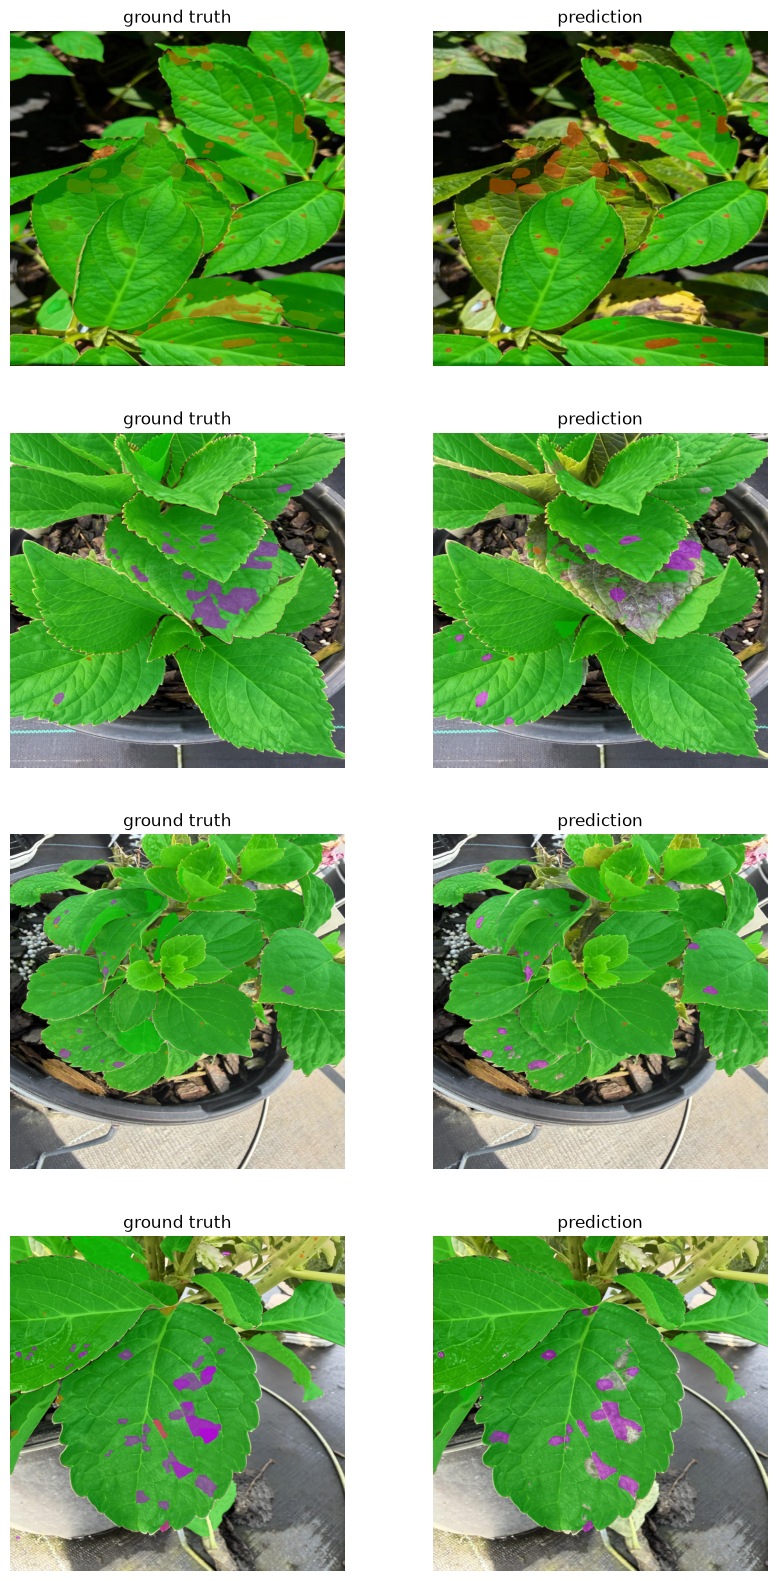

In [9]:
def overlay(image, masks, names):
    out = np.array(image, dtype=float)
    for m, n in zip(masks, names):
        out[m] = 0.5 * out[m] + 0.5 * np.array(COLORS.get(n, (255, 255, 0)))
    return out.astype(np.uint8)


N = 4
fig, axes = plt.subplots(N, 2, figsize=(10, 5 * N))
for row, img in zip(axes, coco_gt.loadImgs(list(predictions)[:N])):
    image = Image.open(TEST_DIR / img["file_name"]).convert("RGB")
    anns = coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=img["id"]))
    masks, names, confidences = predictions[img["id"]]
    keep = confidences >= THRESHOLD
    row[0].imshow(overlay(image, [coco_gt.annToMask(a).astype(bool) for a in anns], [cat_names[a["category_id"]] for a in anns]))
    row[1].imshow(overlay(image, masks[keep], names[keep]))
    row[0].set_title("ground truth"); row[1].set_title("prediction")
    for ax in row:
        ax.axis("off")